In [1]:
import pandas as pd 

com_calls = pd.read_csv("Pv_conts.csv")

In [2]:
com_calls.shape

(150, 93001)

In [3]:
import numpy as np

com_calls = com_calls.replace('0/1', np.nan)

com_calls = com_calls.replace('0/1', np.nan)

com_calls = com_calls.replace('1/1', 1)

com_calls = com_calls.replace('0/0', 0)

com_calls = com_calls.replace('./.', np.nan)

In [4]:
com_calls_fun = com_calls.iloc[:,:10000]
com_calls_fun.shape

(150, 10000)

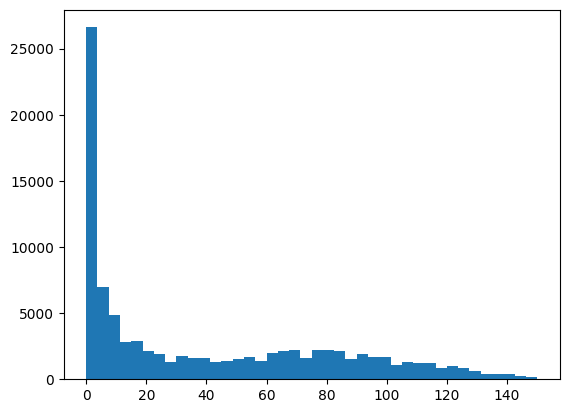

In [5]:
import matplotlib.pyplot as plt

plt.hist(com_calls.isna().sum(axis=0),40)
plt.show()

In [6]:
com_calls_feat_clean = com_calls.loc[:, com_calls.isna().sum() <= 30]
com_calls_feat_clean.shape

(150, 50054)

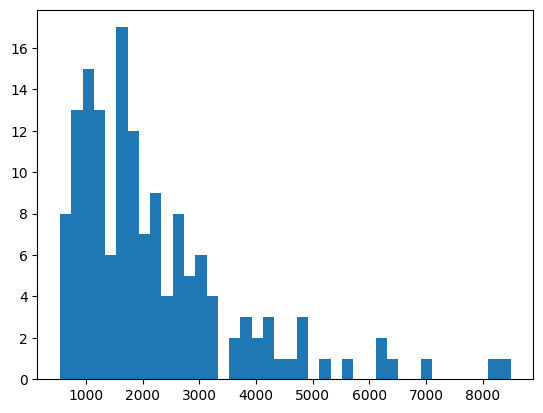

In [7]:
import matplotlib.pyplot as plt

plt.hist(com_calls_feat_clean.isna().sum(axis=1),40)
plt.show()

In [8]:
com_calls_samp_clean = com_calls_feat_clean.loc[com_calls_feat_clean.isna().sum(axis=1) <= 5000, :]
com_calls_samp_clean.shape

(142, 50054)

In [9]:
com_calls_samp_clean = com_calls_samp_clean.drop('Species', axis='columns')
com_calls_samp_clean = com_calls_samp_clean.set_index('Sample')

com_calls_samp_clean.head()

,PvP01_01_v1 4052,PvP01_01_v1 41174,PvP01_01_v1 41198,PvP01_01_v1 41246,PvP01_01_v1 41251,PvP01_01_v1 41284,PvP01_01_v1 41343,PvP01_01_v1 41367,PvP01_01_v1 41369,PvP01_01_v1 41391,...,PvP01_API_v1 14641,PvP01_API_v1 18211,PvP01_API_v1 18390,PvP01_API_v1 20013,PvP01_API_v1 23818,PvP01_API_v1 23912,PvP01_API_v1 26449,PvP01_MIT_v1 2036,PvP01_MIT_v1 4510,PvP01_MIT_v1 4640
Sample,,,,,,,,,,,,,,,,,,,,,
PJ0277-C,NaN,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1,1,1.0
PJ0273-C,0.0,NaN,0.0,0.0,0.0,0.0,NaN,NaN,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0.0
PD0168-C,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,...,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1,1,1.0
PJ0167-C,NaN,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1,1,1.0
Thailand_VKTS_36,NaN,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,...,NaN,1.0,NaN,1.0,NaN,NaN,NaN,1,1,1.0


In [10]:
from sklearn.impute import KNNImputer

imputer = KNNImputer()
com_calls_imp = imputer.fit_transform(com_calls_samp_clean)

In [11]:
com_calls_imp = pd.DataFrame(com_calls_imp, index=com_calls_samp_clean.index, columns=com_calls_samp_clean.columns)

In [12]:
com_calls_bin = com_calls_imp.round()
com_calls_bin.head()

,PvP01_01_v1 4052,PvP01_01_v1 41174,PvP01_01_v1 41198,PvP01_01_v1 41246,PvP01_01_v1 41251,PvP01_01_v1 41284,PvP01_01_v1 41343,PvP01_01_v1 41367,PvP01_01_v1 41369,PvP01_01_v1 41391,...,PvP01_API_v1 14641,PvP01_API_v1 18211,PvP01_API_v1 18390,PvP01_API_v1 20013,PvP01_API_v1 23818,PvP01_API_v1 23912,PvP01_API_v1 26449,PvP01_MIT_v1 2036,PvP01_MIT_v1 4510,PvP01_MIT_v1 4640
Sample,,,,,,,,,,,,,,,,,,,,,
PJ0277-C,0.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0
PJ0273-C,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
PD0168-C,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,...,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
PJ0167-C,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0
Thailand_VKTS_36,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [13]:
pwd()

'/jupyter/work/Location_prep'

In [14]:
loc_info = pd.read_csv("sample_conts.csv")

In [15]:
loc_info = loc_info.set_index('Sample')
loc_info

,Cont
Sample,
PJ0277-C,SE_Asia
PJ0273-C,SE_Asia
PD0168-C,SE_Asia
PJ0167-C,SE_Asia
Thailand_VKTS_36,SE_Asia
...,...
QS0093-C,Africa
QS0124-C,Africa
QS0002-C,Africa


In [16]:
com_calls_bin['Continent'] = 0

for item in com_calls_bin.index: 
    com_calls_bin.loc[item,'Continent'] = loc_info.loc[item,'Cont']

In [20]:
com_calls_bin.head()

,PvP01_01_v1 4052,PvP01_01_v1 41174,PvP01_01_v1 41198,PvP01_01_v1 41246,PvP01_01_v1 41251,PvP01_01_v1 41284,PvP01_01_v1 41343,PvP01_01_v1 41367,PvP01_01_v1 41369,PvP01_01_v1 41391,...,PvP01_API_v1 18211,PvP01_API_v1 18390,PvP01_API_v1 20013,PvP01_API_v1 23818,PvP01_API_v1 23912,PvP01_API_v1 26449,PvP01_MIT_v1 2036,PvP01_MIT_v1 4510,PvP01_MIT_v1 4640,Continent
Sample,,,,,,,,,,,,,,,,,,,,,
PJ0277-C,0.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,SE_Asia
PJ0273-C,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,SE_Asia
PD0168-C,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,SE_Asia
PJ0167-C,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,SE_Asia
Thailand_VKTS_36,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,SE_Asia


In [21]:
from sklearn.model_selection import train_test_split

loc_train, loc_test= train_test_split(com_calls_bin,
                                   random_state=104, 
                                   test_size=0.25, stratify= com_calls_bin['Continent'])

In [ ]:
com_calls_bin.to_csv('Pv_loc_table.csv')

In [26]:
loc_train.to_csv('Pv_loc_train.csv')
loc_test.to_csv('Pv_loc_test.csv')